In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

In [2]:
image_path = r"C:\Users\admin\Documents\DSIP\exp-8 image.jpg"

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

print("Image loaded successfully")
print("Shape:", image.shape)

Image loaded successfully
Shape: (918, 736)


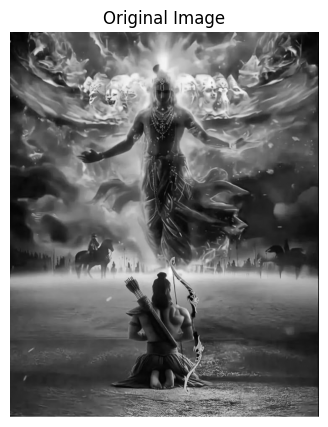

In [3]:
plt.figure(figsize=(6, 5))

plt.imshow(
    image,
    cmap='gray'
)

plt.title('Original Image')
plt.axis('off')

plt.show()

In [4]:
histogram = cv2.calcHist(
    [image],
    [0],
    None,
    [256],
    [0, 256]
)

print("Histogram calculated successfully")

Histogram calculated successfully


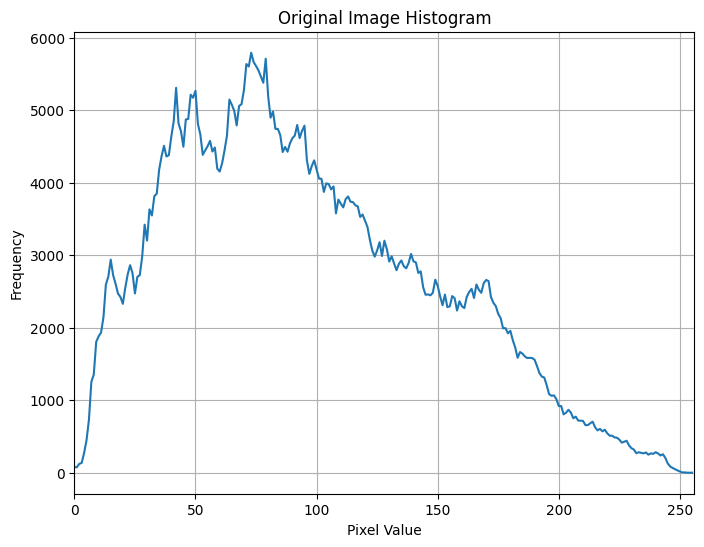

In [5]:
plt.figure(figsize=(8, 6))

plt.title('Original Image Histogram')
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.plot(histogram)

plt.xlim([0, 256])
plt.grid(True)

plt.show()

In [6]:
equalized_image = cv2.equalizeHist(image)

print("Histogram equalization completed")

Histogram equalization completed


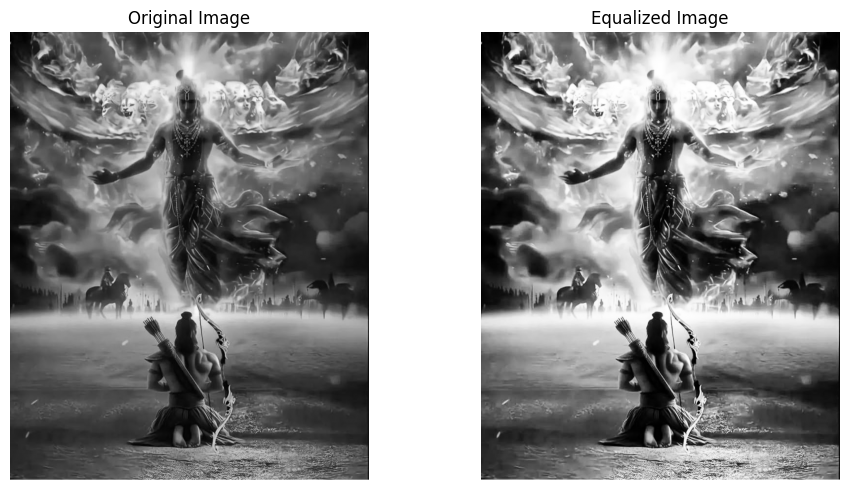

In [7]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)

plt.title('Original Image')

plt.imshow(
    image,
    cmap='gray'
)

plt.axis('off')


plt.subplot(1, 2, 2)

plt.title('Equalized Image')

plt.imshow(
    equalized_image,
    cmap='gray'
)

plt.axis('off')

plt.tight_layout()

plt.show()

In [8]:
equalized_histogram = cv2.calcHist(
    [equalized_image],
    [0],
    None,
    [256],
    [0, 256]
)

print("Equalized histogram calculated successfully")

Equalized histogram calculated successfully


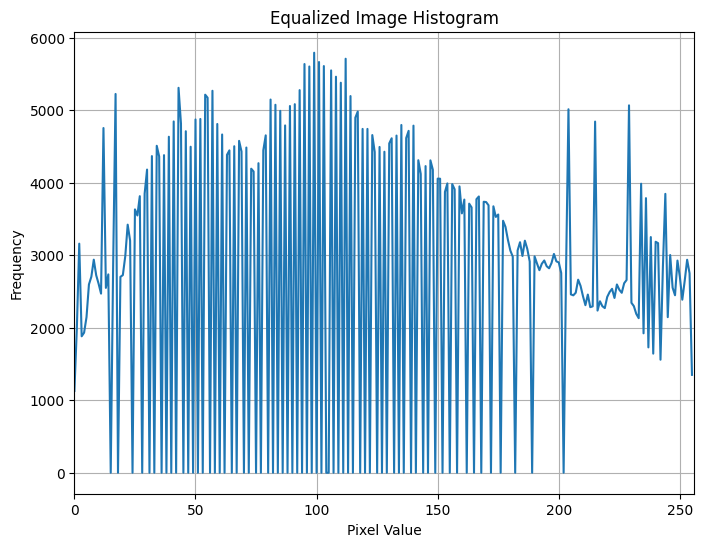

In [9]:
plt.figure(figsize=(8, 6))

plt.title('Equalized Image Histogram')

plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.plot(equalized_histogram)
plt.xlim([0, 256])
plt.grid(True)

plt.show()

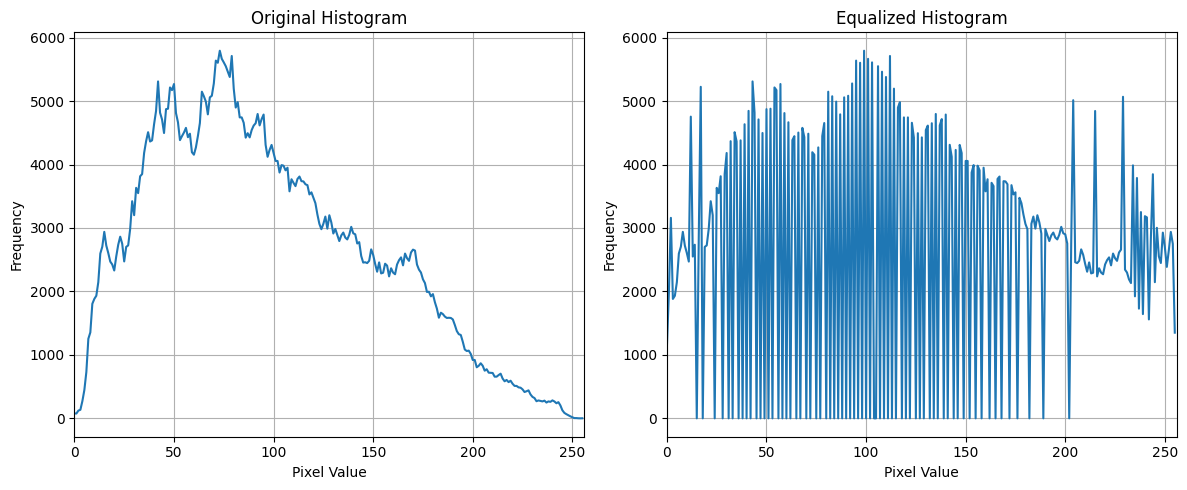

In [10]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.title('Original Histogram')

plt.plot(histogram)

plt.xlabel('Pixel Value')
plt.ylabel('Frequency')

plt.xlim([0, 256])
plt.grid(True)


plt.subplot(1, 2, 2)

plt.title('Equalized Histogram')

plt.plot(equalized_histogram)

plt.xlabel('Pixel Value')
plt.ylabel('Frequency')

plt.xlim([0, 256])
plt.grid(True)

plt.tight_layout()

plt.show()

In [15]:
source_path = r"C:\Users\admin\Documents\DSIP\exp-8 image.jpg"

reference_path = r"C:\Users\admin\Documents\DSIP\noisy.jpg"

source_image = cv2.imread(
    source_path,
    cv2.IMREAD_GRAYSCALE
)

reference_image = cv2.imread(
    reference_path,
    cv2.IMREAD_GRAYSCALE
)

if source_image is None:
    print("Error: Source image not found.")
else:
    print("Source image loaded successfully.")

if reference_image is None:
    print("Error: Reference image not found.")
else:
    print("Reference image loaded successfully.")

Source image loaded successfully.
Reference image loaded successfully.


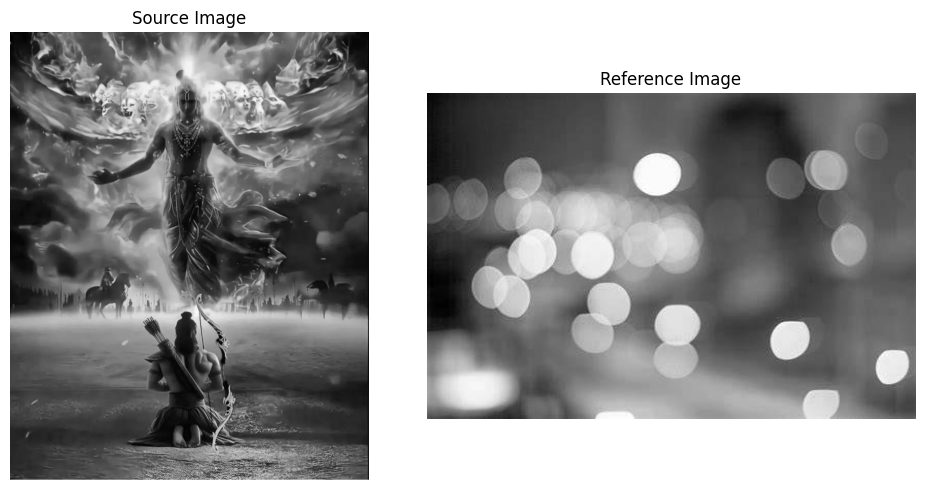

In [16]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)

plt.title('Source Image')

plt.imshow(
    source_image,
    cmap='gray'
)

plt.axis('off')


plt.subplot(1, 2, 2)

plt.title('Reference Image')

if reference_image is not None:
    plt.imshow(
        reference_image,
        cmap='gray'
    )
else:
    plt.text(0.5, 0.5, 'Reference image not found', ha='center', va='center')

plt.axis('off')

plt.tight_layout()

plt.show()

In [17]:
source_hist = cv2.calcHist(
    [source_image],
    [0],
    None,
    [256],
    [0, 256]
)

reference_hist = cv2.calcHist(
    [reference_image],
    [0],
    None,
    [256],
    [0, 256]
)

print("Source and reference histograms calculated")

Source and reference histograms calculated


In [18]:
source_hist /= source_hist.sum()

reference_hist /= reference_hist.sum()

print("Histograms normalized successfully")
print("Source histogram sum:", source_hist.sum())
print("Reference histogram sum:", reference_hist.sum())

Histograms normalized successfully
Source histogram sum: 1.0
Reference histogram sum: 1.0


In [19]:
source_hist /= source_hist.sum()

reference_hist /= reference_hist.sum()

print("Histograms normalized successfully")
print("Source histogram sum:", source_hist.sum())
print("Reference histogram sum:", reference_hist.sum())

Histograms normalized successfully
Source histogram sum: 1.0
Reference histogram sum: 1.0


In [20]:
source_cdf = source_hist.cumsum()

reference_cdf = reference_hist.cumsum()

print("CDFs calculated successfully")

CDFs calculated successfully


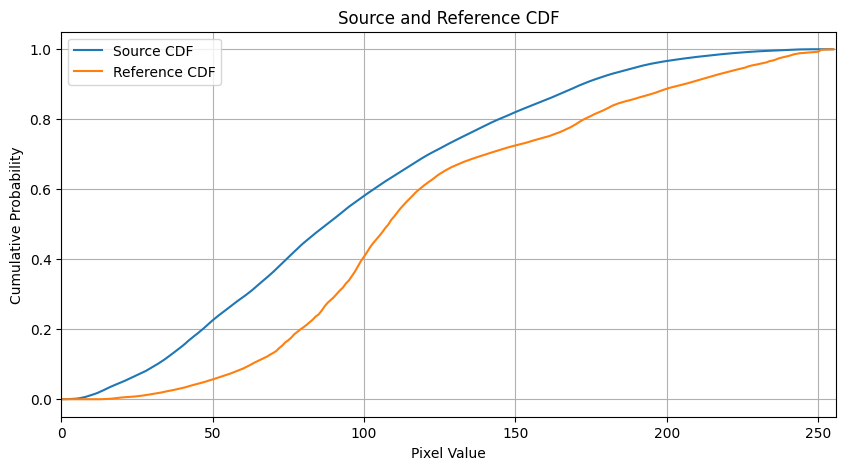

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    source_cdf,
    label='Source CDF'
)

plt.plot(
    reference_cdf,
    label='Reference CDF'
)

plt.title('Source and Reference CDF')

plt.xlabel('Pixel Value')
plt.ylabel('Cumulative Probability')

plt.xlim([0, 256])

plt.grid(True)

plt.legend()

plt.show()

In [22]:
mapping = np.interp(
    source_cdf,
    reference_cdf,
    range(256)
)

matched_image = mapping[source_image]

matched_image = matched_image.astype(
    np.uint8
)

print("Histogram matching completed")

Histogram matching completed


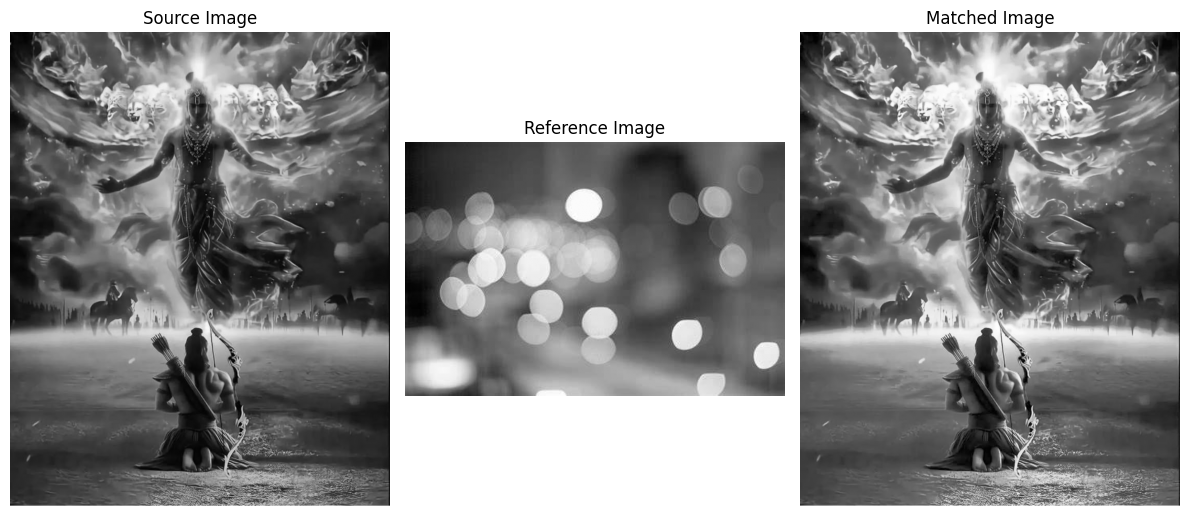

In [23]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.title('Source Image')
plt.imshow(
    source_image,
    cmap='gray'
)

plt.axis('off')


plt.subplot(1, 3, 2)
plt.title('Reference Image')
plt.imshow(
    reference_image,
    cmap='gray'
)

plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Matched Image')
plt.imshow(
    matched_image,
    cmap='gray'
)
plt.axis('off')
plt.tight_layout()

plt.show()

In [24]:
matched_hist = cv2.calcHist(
    [matched_image],
    [0],
    None,
    [256],
    [0, 256]
)

print("Matched histogram calculated successfully")

Matched histogram calculated successfully


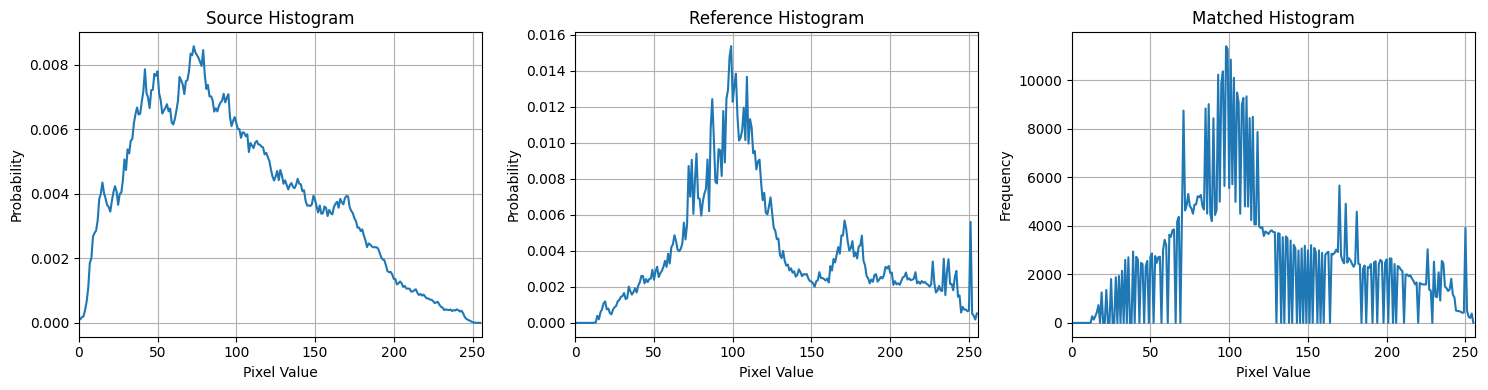

In [25]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.plot(source_hist)
plt.title('Source Histogram')

plt.xlabel('Pixel Value')
plt.ylabel('Probability')
plt.xlim([0, 256])
plt.grid(True)


plt.subplot(1, 3, 2)
plt.plot(reference_hist)
plt.title('Reference Histogram')

plt.xlabel('Pixel Value')
plt.ylabel('Probability')
plt.xlim([0, 256])
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(matched_hist)
plt.title('Matched Histogram')

plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.xlim([0, 256])
plt.grid(True)
plt.tight_layout()

plt.show()

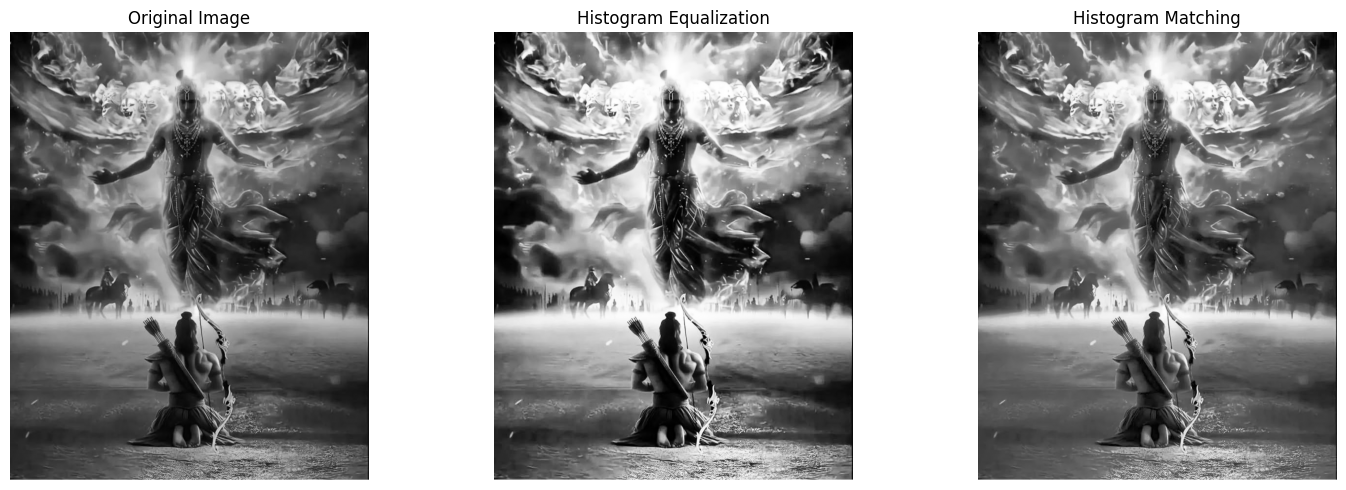

In [26]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(
    image,
    cmap='gray'
)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)

plt.imshow(
    equalized_image,
    cmap='gray'
)
plt.title('Histogram Equalization')
plt.axis('off')

plt.subplot(1, 3, 3)

plt.imshow(
    matched_image,
    cmap='gray'
)
plt.title('Histogram Matching')
plt.axis('off')
plt.tight_layout()

plt.show()